In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
vmt = pd.read_csv("VMT_2022v1_full_annual_20240226_monthly_18jun2024_nf_v4.csv", comment="#", low_memory=False)

vmt_cols = [
    'country_cd','region_cd','tribal_code','census_tract_cd','shape_id','scc',
    'CD','MSR','activity_type','ann_parm_value','calc_year','date_updated',
    'data_set_id','jan_value','feb_value','mar_value','apr_value','may_value',
    'jun_value','jul_value','aug_value','sep_value','oct_value','nov_value',
    'dec_value','comment'
]
vmt.columns = vmt_cols

In [14]:
vmt["ann_parm_value"] = pd.to_numeric(vmt["ann_parm_value"], errors="coerce")

vmt["region_cd_str"] = vmt["region_cd"].astype(str).str.strip()
mask_cook = vmt["region_cd_str"] == "17031"

vmt["scc_str"]   = vmt["scc"].astype(str).str.zfill(10)
vmt["src_type"]  = vmt["scc_str"].str[4:6]   # 5th–6th digits → 52,53,61,62
vmt["fuel_type"] = vmt["scc_str"].str[2:4]   # 3rd–4th digits → 01,02,03,...

target_types = ["52", "53", "61", "62"]
mask_types = vmt["src_type"].isin(target_types)

vmt_cook = vmt[mask_cook & mask_types].copy()

In [16]:
fuel_label_map = {
    "01": "Gasoline",
    "02": "Diesel",
    "03": "CNG"
}
vmt_cook["fuel_label"] = vmt_cook["fuel_type"].map(fuel_label_map).fillna(vmt_cook["fuel_type"])

total_vmt_by_fuel = (
    vmt_cook.groupby("fuel_label")["ann_parm_value"]
    .sum()
    .sort_values(ascending=False)
)

Total Cook County annual VMT by fuel type (52/53/61/62 only):
fuel_label
Diesel      2.641623e+09
Gasoline    3.768085e+08
CNG         1.396308e+07
Name: ann_parm_value, dtype: float64


In [18]:
dist_file = "VMT_DIST_Moves4.xlsx"
sheet_name = "MOVES % VMTs"

dist_raw = pd.read_excel(dist_file, sheet_name=sheet_name, header=None)

dist_slice = dist_raw.iloc[3:34, :]

model_year = pd.to_numeric(dist_slice.iloc[:, 0], errors="coerce")

dist_52 = pd.to_numeric(dist_slice.iloc[:, 2], errors="coerce")  # column C
dist_53 = pd.to_numeric(dist_slice.iloc[:, 3], errors="coerce")  # column D
dist_61 = pd.to_numeric(dist_slice.iloc[:, 4], errors="coerce")  # column E
dist_62 = pd.to_numeric(dist_slice.iloc[:, 5], errors="coerce")  # column F

dist_df = pd.DataFrame({
    "model_year": model_year,
    "52": dist_52,
    "53": dist_53,
    "61": dist_61,
    "62": dist_62,
}).dropna()


In [19]:
for code in target_types:
    col_sum = dist_df[code].sum()
    if col_sum != 0:
        dist_df[code] = dist_df[code] / col_sum


In [20]:
vmt_by_year = dist_df.copy()
for code in target_types:
    total_vmt = total_vmt_by_type.get(code, 0.0)
    vmt_by_year[code] = vmt_by_year[code] * total_vmt

# Optional: long-format table if you want to inspect
vmt_long = vmt_by_year.melt(
    id_vars="model_year",
    value_vars=target_types,
    var_name="src_type",
    value_name="VMT"
)

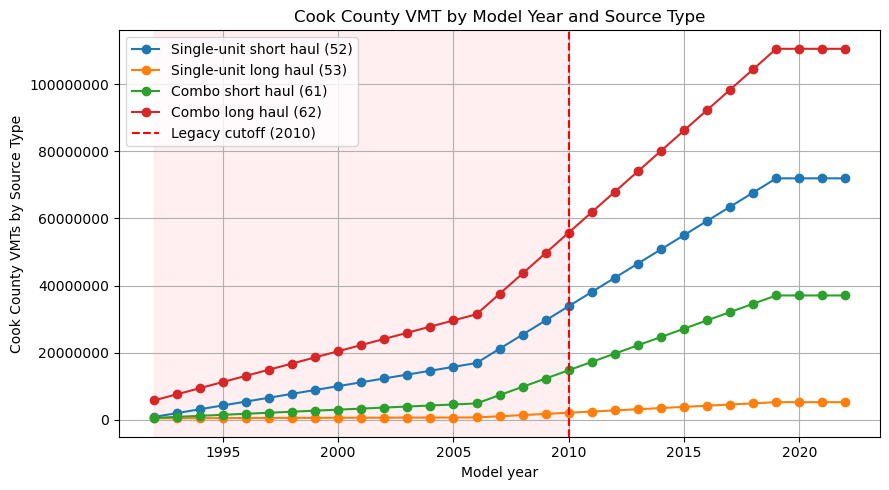

In [24]:
plt.figure(figsize=(9, 5))

label_map = {
    "52": "Single-unit short haul (52)",
    "53": "Single-unit long haul (53)",
    "61": "Combo short haul (61)",
    "62": "Combo long haul (62)",
}

for code in target_types:
    plt.plot(
        vmt_by_year["model_year"],
        vmt_by_year[code],
        marker="o",
        label=label_map.get(code, code),
    )

    # Shade everything ≤ 2009
plt.axvspan(vmt_by_year["model_year"].min(), 2010, color="pink", alpha=0.25)
plt.axvline(2010, color="red", linestyle="--", label="Legacy cutoff (2010)")

plt.xlabel("Model year")
plt.ylabel("Cook County VMTs by Source Type")
plt.ticklabel_format(style='plain', axis='y')
plt.title("Cook County VMT by Model Year and Source Type")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()